EXPECTATION DECIDER DATASET
   study_hours  attendance group_discussion  previous_test_score  \
0          8.7        78.5              Yes                   65   
1         19.1        45.0               No                   93   
2         15.2        49.7              Yes                   77   
3         12.8        93.9              Yes                   68   
4          4.8        76.4               No                   45   

  final_exam_pass  
0            Pass  
1            Pass  
2            Pass  
3            Pass  
4            Pass  

Dataset Shape: (200, 5)

Missing Values:
 study_hours            0
attendance             0
group_discussion       0
previous_test_score    0
final_exam_pass        0
dtype: int64

1. UNDERSTANDING PROBABILITY
Probability = Number of favourable outcomes / Total outcomes
Total Students: 200
Students Passed: 169
Students Failed: 31
P(Pass) = 0.845
P(Fail) = 0.155
P(Study more than 10 hours) = 0.52
P(Attendance above 80%) = 0.33
P(Group Disc

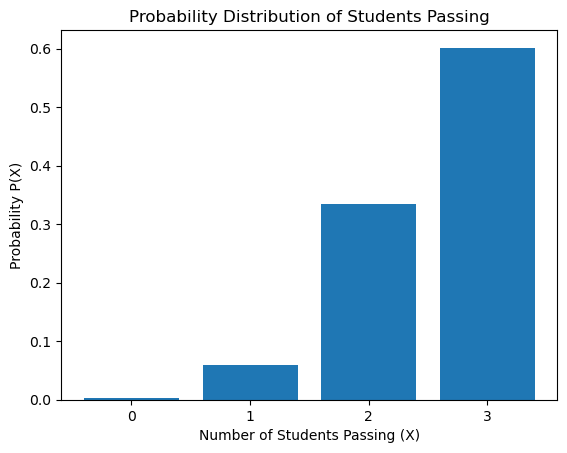


4. VENN DIAGRAM
Study more than 10 hours only: 69
Attendance above 80% only: 31
Both conditions: 35
Neither condition: 65


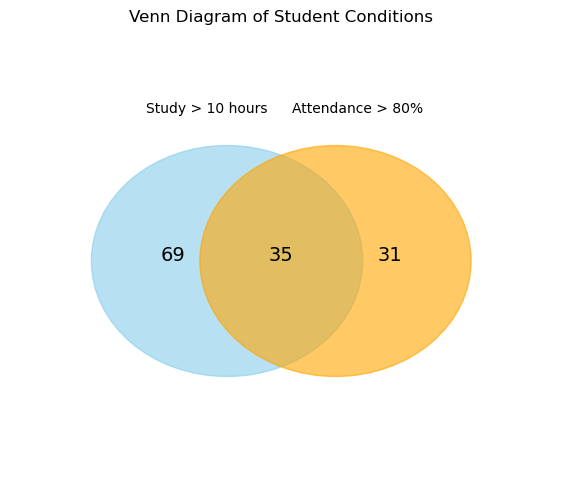


5. CONTINGENCY TABLE
final_exam_pass   Pass  Fail
group_discussion            
Yes                 91    13
No                  78    18
Joint P(Discussion AND Pass) = 0.455
Marginal P(Pass) = 0.845
Conditional P(Pass | Discussion) = 0.875

6. UNDERSTANDING RELATIONSHIPS
P(Pass) = 0.845
P(Pass | Discussion) = 0.875
The events are dependent in this dataset.
The events are not mutually exclusive if at least
one student both participated and passed: True

7. BAYES' THEOREM
P(Pass) = 0.6666666666666666
P(Pass | High Attendance) = 0.7777777777777777
Percentage = 77.77777777777777 %

FINAL SUMMARY
Total students: 200
Students passed: 169
Students failed: 31
Empirical pass probability: 0.845
Mean number passing out of 3: 2.535
Variance: 0.389
Pass probability given group discussion: 0.875
Bayes probability for high attendance: 0.778

Dataset saved as expectation_decider_dataset.csv


In [4]:

# PR1: Expectation Decider
# Mathematics and Advanced Statistics

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import hypergeom

# ==================================================
# 1. GENERATE DATASET OF 200 STUDENTS
# ==================================================

np.random.seed(42)

n = 200

study_hours = np.round(np.random.uniform(2, 20, n), 1)
attendance = np.round(np.random.uniform(40, 100, n), 1)
group_discussion = np.random.choice(["Yes", "No"], n)

previous_test_score = np.clip(
    np.round(
        25 + study_hours * 2 + attendance * 0.25
        + np.random.normal(0, 10, n)
    ), 0, 100
).astype(int)

# Generate pass/fail results using student performance factors
pass_probability = (
    0.05
    + 0.025 * study_hours
    + 0.003 * attendance
    + 0.004 * previous_test_score
    + 0.08 * (group_discussion == "Yes")
)

pass_probability = np.clip(pass_probability, 0.05, 0.95)

final_exam_pass = np.where(
    np.random.random(n) < pass_probability,
    "Pass",
    "Fail"
)

df = pd.DataFrame({
    "study_hours": study_hours,
    "attendance": attendance,
    "group_discussion": group_discussion,
    "previous_test_score": previous_test_score,
    "final_exam_pass": final_exam_pass
})

print("EXPECTATION DECIDER DATASET")
print(df.head())

print("\nDataset Shape:", df.shape)
print("\nMissing Values:\n", df.isnull().sum())

df.to_csv("C:/Users/mansi/Downloads/expectation_decider_dataset.csv", index=False)


# ==================================================
# 2. UNDERSTANDING PROBABILITY
# ==================================================

print("\n1. UNDERSTANDING PROBABILITY")

print("Probability = Number of favourable outcomes / Total outcomes")

total_students = len(df)
pass_count = (df["final_exam_pass"] == "Pass").sum()
fail_count = (df["final_exam_pass"] == "Fail").sum()

print("Total Students:", total_students)
print("Students Passed:", pass_count)
print("Students Failed:", fail_count)

print("P(Pass) =", pass_count / total_students)
print("P(Fail) =", fail_count / total_students)

print("P(Study more than 10 hours) =",
      (df["study_hours"] > 10).mean())

print("P(Attendance above 80%) =",
      (df["attendance"] > 80).mean())

print("P(Group Discussion = Yes) =",
      (df["group_discussion"] == "Yes").mean())


# ==================================================
# 3. EMPIRICAL AND THEORETICAL PROBABILITY
# ==================================================

print("\n2. TYPES OF PROBABILITY")

# Empirical probability from observed data
empirical_probability = pass_count / total_students

print("Empirical P(Pass) =", empirical_probability)

# Theoretical probability: two equally likely outcomes
# under an equal-likelihood assumption
theoretical_probability = 1 / 2

print("Theoretical P(Pass) =", theoretical_probability)


# ==================================================
# 4. RANDOM VARIABLE AND PROBABILITY DISTRIBUTION
# ==================================================

print("\n3. RANDOM VARIABLE AND PROBABILITY DISTRIBUTION")

# X = Number of students passing out of 3 selected students
# Sampling is without replacement from the 200 students.

N = total_students
K = pass_count
sample_size = 3

x = np.arange(0, 4)

probabilities = hypergeom.pmf(
    x, N, K, sample_size
)

distribution = pd.DataFrame({
    "X (Number Passing)": x,
    "P(X)": probabilities
})

print(distribution)

mean_X = np.sum(x * probabilities)
variance_X = np.sum((x - mean_X) ** 2 * probabilities)

print("Mean =", mean_X)
print("Variance =", variance_X)

plt.bar(x, probabilities)
plt.xlabel("Number of Students Passing (X)")
plt.ylabel("Probability P(X)")
plt.title("Probability Distribution of Students Passing")
plt.xticks(x)
plt.show()


# ==================================================
# 5. VENN DIAGRAM
# ==================================================

print("\n4. VENN DIAGRAM")

A = df["study_hours"] > 10
B = df["attendance"] > 80

only_A = (A & ~B).sum()
only_B = (B & ~A).sum()
both = (A & B).sum()
neither = (~A & ~B).sum()

print("Study more than 10 hours only:", only_A)
print("Attendance above 80% only:", only_B)
print("Both conditions:", both)
print("Neither condition:", neither)

from matplotlib.patches import Circle

fig, ax = plt.subplots(figsize=(7, 6))

circle1 = Circle((0.4, 0.5), 0.25, color="skyblue", alpha=0.6)
circle2 = Circle((0.6, 0.5), 0.25, color="orange", alpha=0.6)

ax.add_patch(circle1)
ax.add_patch(circle2)

ax.text(0.30, 0.5, str(only_A), ha="center", fontsize=14)
ax.text(0.70, 0.5, str(only_B), ha="center", fontsize=14)
ax.text(0.50, 0.5, str(both), ha="center", fontsize=14)

ax.text(0.25, 0.82, "Study > 10 hours")
ax.text(0.52, 0.82, "Attendance > 80%")

ax.set_title("Venn Diagram of Student Conditions")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")
plt.show()


# ==================================================
# 6. CONTINGENCY TABLE AND PROBABILITIES
# ==================================================

print("\n5. CONTINGENCY TABLE")

table = pd.crosstab(
    df["group_discussion"],
    df["final_exam_pass"]
).reindex(
    index=["Yes", "No"],
    columns=["Pass", "Fail"],
    fill_value=0
)

print(table)

discussion_pass = table.loc["Yes", "Pass"]

joint_probability = discussion_pass / total_students
marginal_probability = pass_count / total_students

yes_total = table.loc["Yes"].sum()

conditional_probability = (
    discussion_pass / yes_total if yes_total > 0 else 0
)

print("Joint P(Discussion AND Pass) =", joint_probability)
print("Marginal P(Pass) =", marginal_probability)
print("Conditional P(Pass | Discussion) =",
      conditional_probability)


# ==================================================
# 7. UNDERSTANDING RELATIONSHIPS
# ==================================================

print("\n6. UNDERSTANDING RELATIONSHIPS")

print("P(Pass) =", marginal_probability)
print("P(Pass | Discussion) =", conditional_probability)

if np.isclose(conditional_probability, marginal_probability):
    print("The events are independent in this dataset.")
else:
    print("The events are dependent in this dataset.")

print("The events are not mutually exclusive if at least")
print("one student both participated and passed:",
      discussion_pass > 0)


# ==================================================
# 8. BAYES' THEOREM
# ==================================================

print("\n7. BAYES' THEOREM")

# Given in the PDF:
# P(High Attendance | Pass) = 0.70
# P(High Attendance | Fail) = 0.40
# P(High Attendance) = 0.60

P_H_given_P = 0.70
P_H_given_F = 0.40
P_H = 0.60

# First calculate P(Pass) using total probability
P_P = (P_H - P_H_given_F) / (
    P_H_given_P - P_H_given_F
)

# Apply Bayes' theorem
P_P_given_H = (P_H_given_P * P_P) / P_H

print("P(Pass) =", P_P)
print("P(Pass | High Attendance) =", P_P_given_H)
print("Percentage =", P_P_given_H * 100, "%")


# ==================================================
# 9. FINAL SUMMARY
# ==================================================

print("\nFINAL SUMMARY")

print("Total students:", total_students)
print("Students passed:", pass_count)
print("Students failed:", fail_count)

print("Empirical pass probability:",
      round(empirical_probability, 3))

print("Mean number passing out of 3:",
      round(mean_X, 3))

print("Variance:",
      round(variance_X, 3))

print("Pass probability given group discussion:",
      round(conditional_probability, 3))

print("Bayes probability for high attendance:",
      round(P_P_given_H, 3))

print("\nDataset saved as expectation_decider_dataset.csv")
